# Домашняя работа № 4. Анализ данных Titanic с помощью pandas

В этой работе разбираю таблицу пассажиров «Титаника» (`train.csv`). Нужно пройти полный цикл работы с данными: загрузить файл, посмотреть на структуру и типы признаков, найти пропуски, аккуратно их заполнить, добавить несколько новых столбцов, посчитать статистики, построить выборки и графики, а затем сохранить результаты в CSV.

Основные библиотеки: **pandas**, **NumPy** и **matplotlib**.


## 1. Загрузка таблицы и первый осмотр

Сначала читаю CSV в `DataFrame`, сразу делаю копию исходных данных — так позже можно сравнить таблицу до и после очистки. Затем смотрю начало и конец набора, размер, список столбцов и типы данных.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

raw_passengers = pd.read_csv("train.csv")
passengers = raw_passengers.copy()

print("Первые строки:")
display(passengers.head())
print("Последние строки:")
display(passengers.tail())


Первые строки:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Последние строки:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [2]:
rows, cols = passengers.shape
print(f"В таблице {rows} строк и {cols} столбцов")
print("Названия столбцов:", passengers.columns.tolist())
print()
print("Типы данных:")
print(passengers.dtypes)


В таблице 891 строк и 12 столбцов
Названия столбцов: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Типы данных:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


## 2. Смысловые группы признаков

Хотя `Pclass` хранится как целое число, это не количественный показатель: значения 1, 2 и 3 — это названия классов обслуживания, а не величина, с которой имеет смысл считать среднее. Между первым и третьим классом нет «двух единиц класса» в числовом смысле, поэтому признак удобнее считать категориальным.

`Survived`, `Sex` и `Embarked` тоже относятся к категориям. Возраст, число родственников и стоимость билета — количественные поля. Имя, номер билета и каюта — текстовые.


In [3]:
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]
category_cols = ["Survived", "Pclass", "Sex", "Embarked"]
text_cols = ["Name", "Ticket", "Cabin"]

print("Количественные:", numeric_cols)
print("Категориальные:", category_cols)
print("Текстовые:", text_cols)
print()
print("Почему Pclass лучше считать категорией:")
print(passengers["Pclass"].value_counts().sort_index())


Количественные: ['Age', 'SibSp', 'Parch', 'Fare']
Категориальные: ['Survived', 'Pclass', 'Sex', 'Embarked']
Текстовые: ['Name', 'Ticket', 'Cabin']

Почему Pclass лучше считать категорией:
Pclass
1    216
2    184
3    491
Name: count, dtype: int64


## 3. Описательные статистики

Для возраста, числа братьев/сестёр или супругов, числа родителей/детей и стоимости билета считаю среднее, медиану, минимум, максимум и стандартное отклонение. Дополнительно смотрю, сколько пассажиров ехало в каждом классе и сколько разных портов посадки встречается в данных.


In [4]:
numeric_summary = pd.DataFrame({
    "среднее": passengers[numeric_cols].mean(),
    "медиана": passengers[numeric_cols].median(),
    "минимум": passengers[numeric_cols].min(),
    "максимум": passengers[numeric_cols].max(),
    "станд. отклонение": passengers[numeric_cols].std(),
})
display(numeric_summary)

print("Число пассажиров по классу:")
print(passengers["Pclass"].value_counts().sort_index())
print()
print("Уникальных значений Embarked (без учёта пропусков):", passengers["Embarked"].nunique())
print(passengers["Embarked"].value_counts(dropna=False))


,среднее,медиана,минимум,максимум,станд. отклонение
Age,29.699118,28.0000,0.42,80.0000,14.526497
SibSp,0.523008,0.0000,0.00,8.0000,1.102743
Parch,0.381594,0.0000,0.00,6.0000,0.806057
Fare,32.204208,14.4542,0.00,512.3292,49.693429


Число пассажиров по классу:
Pclass
1    216
2    184
3    491
Name: count, dtype: int64

Уникальных значений Embarked (без учёта пропусков): 3
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


## 4. Поиск пропусков

Для каждого столбца считаю, сколько значений отсутствует и какую долю таблицы это составляет. Так проще решить, что заполнять, а что лучше убрать.


In [5]:
missing_count = passengers.isna().sum()
missing_share = passengers.isna().mean() * 100

missing_table = pd.DataFrame({
    "число пропусков": missing_count,
    "доля, %": missing_share.round(2),
})
missing_table = missing_table[missing_table["число пропусков"] > 0]
display(missing_table.sort_values("число пропусков", ascending=False))

print("Столбец с наибольшим числом пропусков:", missing_count.idxmax())


,число пропусков,"доля, %"
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Столбец с наибольшим числом пропусков: Cabin


В исходных данных пропуски есть только в трёх столбцах:

- `Age` — около 20% строк, возраст ещё можно восстановить по похожим пассажирам;
- `Embarked` — всего две строки, это можно заполнить самым частым портом;
- `Cabin` — больше трёх четвертей значений пустые, сам номер каюты почти бесполезен, но факт «каюта указана / не указана» может пригодиться.

## 5. Заполнение возраста

Простой способ — подставить одну общую медиану всем, у кого возраст неизвестен. Но медиана у женщин первого класса и у мужчин третьего заметно отличается, поэтому я заполняю пропуски **медианой возраста внутри группы «класс + пол»**. Так оценка ближе к типичному возрасту похожих пассажиров.

Сначала фиксирую статистики возраста до заполнения, затем подставляю групповые медианы и сравниваю показатели.


In [6]:
age_before = pd.Series({
    "среднее": passengers["Age"].mean(),
    "медиана": passengers["Age"].median(),
    "минимум": passengers["Age"].min(),
    "максимум": passengers["Age"].max(),
    "станд. отклонение": passengers["Age"].std(),
    "число заполненных": passengers["Age"].count(),
}, name="до заполнения")

group_age_median = passengers.groupby(["Pclass", "Sex"])["Age"].median()
print("Медиана возраста в группах класс + пол:")
display(group_age_median.unstack())

# Для сравнения: одна общая медиана по всей таблице
overall_age_median = passengers["Age"].median()
print(f"Общая медиана возраста по всей таблице: {overall_age_median:.1f} года")

passengers["Age"] = passengers.groupby(["Pclass", "Sex"])["Age"].transform(
    lambda series: series.fillna(series.median())
)

age_after = pd.Series({
    "среднее": passengers["Age"].mean(),
    "медиана": passengers["Age"].median(),
    "минимум": passengers["Age"].min(),
    "максимум": passengers["Age"].max(),
    "станд. отклонение": passengers["Age"].std(),
    "число заполненных": passengers["Age"].count(),
}, name="после заполнения")

age_compare = pd.concat([age_before, age_after], axis=1)
display(age_compare)
print("Оставшихся пропусков в Age:", int(passengers["Age"].isna().sum()))


Медиана возраста в группах класс + пол:


Sex,female,male
Pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


Общая медиана возраста по всей таблице: 28.0 года


,до заполнения,после заполнения
среднее,29.699118,29.112424
медиана,28.000000,26.000000
минимум,0.420000,0.420000
максимум,80.000000,80.000000
станд. отклонение,14.526497,13.304424
число заполненных,714.000000,891.000000


Оставшихся пропусков в Age: 0


Медиана здесь уместнее среднего: на «Титанике» есть и младенцы, и пассажиры 70–80 лет, а среднее сильнее тянется к таким крайним значениям. Минимум (0,42) и максимум (80) после заполнения не изменились — новых крайних возрастов мы не добавляли.

Среднее снизилось с 29,70 до 29,11, разброс — с 14,53 до 13,30. Общая медиана тоже сдвинулась: с 28 до 26 лет. Это как раз следствие группового заполнения. Большая часть пропусков приходится на третий класс, где групповые медианы ниже (25 лет у мужчин и 21,5 года у женщин). Если бы всем подставляли одну общую медиану 28, итоговая медиана осталась бы на месте, но возраста пассажиров третьего класса были бы завышены.

Исходное распределение возраста при этом не сохраняется полностью: на месте пропусков появляются повторённые медианы групп, то есть в нескольких точках возникает искусственное сгущение. Это плата за то, что столбец становится полным и его можно использовать в расчётах.


## 6. Порт посадки и каюта

Два пропуска в `Embarked` заполняю модой — самым частым портом. Удалять эти строки не обязательно: их всего две, а порт для них можно правдоподобно восстановить.

Для каюты сначала добавляю флаг `HasCabin` (1, если номер указан). Сам столбец `Cabin` удаляю, потому что доля пропусков больше 50% и в таком виде он мало что даёт.


In [7]:
port_mode = passengers["Embarked"].mode().iloc[0]
print(f"Самый частый порт посадки: {port_mode}")
print("Строк с пустым Embarked до заполнения:", int(passengers["Embarked"].isna().sum()))
passengers["Embarked"] = passengers["Embarked"].fillna(port_mode)

passengers["HasCabin"] = passengers["Cabin"].notna().astype(int)
cabin_missing_share = raw_passengers["Cabin"].isna().mean()
print(f"Доля пропусков в Cabin: {cabin_missing_share:.2%}")
if cabin_missing_share > 0.5:
    passengers = passengers.drop(columns=["Cabin"])
    print("Столбец Cabin удалён, флаг HasCabin сохранён.")

print()
print("Пропуски после очистки:")
print(passengers.isna().sum())
print()
shape_compare = pd.DataFrame({
    "до обработки": raw_passengers.shape,
    "после обработки": passengers.shape,
}, index=["строки", "столбцы"])
display(shape_compare)


Самый частый порт посадки: S
Строк с пустым Embarked до заполнения: 2
Доля пропусков в Cabin: 77.10%
Столбец Cabin удалён, флаг HasCabin сохранён.

Пропуски после очистки:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
HasCabin       0
dtype: int64



,до обработки,после обработки
строки,891,891
столбцы,12,12


Строк по-прежнему 891: пустые порты я не выбрасывал, а заполнил. Столбцов стало столько же (12), потому что вместо `Cabin` появился `HasCabin`. Дальше добавлю ещё несколько расчётных признаков.

## 7. Новые признаки

Из имени можно вытащить обращение (`Mr`, `Miss`, `Mrs`, `Master` и другие). По числу родственников считаю размер семьи и признак «путешествовал один». Возраст разобью на диапазоны, чтобы потом сравнить выживаемость по группам.


In [8]:
passengers["Title"] = passengers["Name"].str.extract(r",\s*([^\.]+)\.")
title_aliases = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
passengers["Title"] = passengers["Title"].replace(title_aliases)
frequent_titles = ["Mr", "Miss", "Mrs", "Master"]
passengers["Title"] = passengers["Title"].where(
    passengers["Title"].isin(frequent_titles),
    "Other",
)

passengers["FamilySize"] = passengers["SibSp"] + passengers["Parch"] + 1
passengers["IsAlone"] = (passengers["FamilySize"] == 1).astype(int)

age_bins = [0, 12, 18, 35, 50, 200]
age_labels = [
    "ребёнок (0–12)",
    "подросток (13–18)",
    "молодой (19–35)",
    "взрослый (36–50)",
    "старший (51+)",
]
passengers["AgeGroup"] = pd.cut(
    passengers["Age"],
    bins=age_bins,
    labels=age_labels,
    right=True,
    include_lowest=True,
)

print("Обращения после укрупнения:")
print(passengers["Title"].value_counts())
print()
print("Размер семьи:")
print(passengers["FamilySize"].value_counts().sort_index())
print()
print("Возрастные группы:")
print(passengers["AgeGroup"].value_counts().sort_index())
display(passengers[["Name", "Title", "Age", "AgeGroup", "FamilySize", "IsAlone", "HasCabin"]].head(8))


Обращения после укрупнения:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64

Размер семьи:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

Возрастные группы:
AgeGroup
ребёнок (0–12)        69
подросток (13–18)     70
молодой (19–35)      514
взрослый (36–50)     174
старший (51+)         64
Name: count, dtype: int64


,Name,Title,Age,AgeGroup,FamilySize,IsAlone,HasCabin
0,"Braund, Mr. Owen Harris",Mr,22.0,молодой (19–35),2,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.0,взрослый (36–50),2,0,1
2,"Heikkinen, Miss. Laina",Miss,26.0,молодой (19–35),1,1,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.0,молодой (19–35),2,0,1
4,"Allen, Mr. William Henry",Mr,35.0,молодой (19–35),1,1,0
5,"Moran, Mr. James",Mr,25.0,молодой (19–35),1,1,0
6,"McCarthy, Mr. Timothy J",Mr,54.0,старший (51+),1,1,1
7,"Palsson, Master. Gosta Leonard",Master,2.0,ребёнок (0–12),5,0,0


## 8. Показатели через массивы NumPy

Для нескольких расчётов перевожу нужные столбцы в массивы NumPy и считаю доли и средние с помощью логических масок — без повторных обращений к `groupby`.


In [9]:
survived_arr = passengers["Survived"].to_numpy()
sex_arr = passengers["Sex"].to_numpy()
age_arr = passengers["Age"].to_numpy()
fare_arr = passengers["Fare"].to_numpy()

overall_survival = np.mean(survived_arr) * 100
male_survival = np.mean(survived_arr[sex_arr == "male"]) * 100
female_survival = np.mean(survived_arr[sex_arr == "female"]) * 100

male_age_mean = np.mean(age_arr[sex_arr == "male"])
female_age_mean = np.mean(age_arr[sex_arr == "female"])

male_survived_age = np.mean(age_arr[(sex_arr == "male") & (survived_arr == 1)])
male_lost_age = np.mean(age_arr[(sex_arr == "male") & (survived_arr == 0)])
female_survived_age = np.mean(age_arr[(sex_arr == "female") & (survived_arr == 1)])
female_lost_age = np.mean(age_arr[(sex_arr == "female") & (survived_arr == 0)])

fare_min = np.min(fare_arr)
fare_max = np.max(fare_arr)
fare_mean = np.mean(fare_arr)
age_std = np.std(age_arr, ddof=1)

numpy_stats = pd.DataFrame({
    "показатель": [
        "общая доля выживших, %",
        "доля выживших среди мужчин, %",
        "доля выживших среди женщин, %",
        "средний возраст мужчин",
        "средний возраст женщин",
        "средний возраст выживших мужчин",
        "средний возраст погибших мужчин",
        "средний возраст выживших женщин",
        "средний возраст погибших женщин",
        "минимальная стоимость билета",
        "максимальная стоимость билета",
        "средняя стоимость билета",
        "стандартное отклонение возраста",
    ],
    "значение": [
        overall_survival,
        male_survival,
        female_survival,
        male_age_mean,
        female_age_mean,
        male_survived_age,
        male_lost_age,
        female_survived_age,
        female_lost_age,
        fare_min,
        fare_max,
        fare_mean,
        age_std,
    ],
})
display(numpy_stats)


,показатель,значение
0,"общая доля выживших, %",38.383838
1,"доля выживших среди мужчин, %",18.890815
2,"доля выживших среди женщин, %",74.203822
3,средний возраст мужчин,30.119879
4,средний возраст женщин,27.261146
5,средний возраст выживших мужчин,27.721743
6,средний возраст погибших мужчин,30.678419
7,средний возраст выживших женщин,28.289700
8,средний возраст погибших женщин,24.302469
9,минимальная стоимость билета,0.000000


Уже по этим цифрам видно главный перекос: среди женщин доля спасённых намного выше, чем среди мужчин. Возраст внутри каждого пола у выживших и погибших отличается слабее, чем выживаемость по полу.

## 9. Фильтрация по нескольким условиям

Ниже четыре выборки из уже очищенной таблицы. Операторы `&` и `|` здесь работают так: `&` требует, чтобы выполнялись все условия сразу (логическое «и»), а `|` — чтобы хватило хотя бы одного (логическое «или»). Каждое условие берётся в скобки, иначе приоритет операций в pandas легко даст ошибку или не тот результат.


In [10]:
men_over30_first = passengers[
    (passengers["Sex"] == "male")
    & (passengers["Age"] > 30)
    & (passengers["Pclass"] == 1)
]

young_or_women_alive = passengers[
    ((passengers["Age"] < 18) | (passengers["Sex"] == "female"))
    & (passengers["Survived"] == 1)
]

third_class_mean_fare = passengers.loc[passengers["Pclass"] == 3, "Fare"].mean()
third_class_costly = passengers[
    (passengers["Pclass"] == 3)
    & (passengers["Fare"] > third_class_mean_fare)
]

southampton_20_40 = passengers[
    (passengers["Age"] >= 20)
    & (passengers["Age"] <= 40)
    & (passengers["Embarked"] == "S")
]

filters_summary = pd.DataFrame({
    "условие": [
        "мужчины старше 30 лет из первого класса",
        "выжившие младше 18 лет или женщины",
        "третий класс со стоимостью билета выше средней по этому классу",
        "пассажиры 20–40 лет с портом посадки S",
    ],
    "число пассажиров": [
        len(men_over30_first),
        len(young_or_women_alive),
        len(third_class_costly),
        len(southampton_20_40),
    ],
})
display(filters_summary)
print(f"Средняя цена билета в 3 классе: {third_class_mean_fare:.4f}")
display(men_over30_first.head(8))


,условие,число пассажиров
0,мужчины старше 30 лет из первого класса,96
1,выжившие младше 18 лет или женщины,256
2,третий класс со стоимостью билета выше средней...,152
3,пассажиры 20–40 лет с портом посадки S,407


Средняя цена билета в 3 классе: 13.6756


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin,Title,FamilySize,IsAlone,AgeGroup
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,S,1,Mr,1,1,старший (51+)
30,31,0,1,"Uruchurtu, Don. Manuel E",male,40.0,0,0,PC 17601,27.7208,C,0,Other,1,1,взрослый (36–50)
35,36,0,1,"Holverson, Mr. Alexander Oskar",male,42.0,1,0,113789,52.0000,S,0,Mr,2,0,взрослый (36–50)
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,C,1,Mr,2,0,старший (51+)
55,56,1,1,"Woolner, Mr. Hugh",male,40.0,0,0,19947,35.5000,S,1,Mr,1,1,взрослый (36–50)
62,63,0,1,"Harris, Mr. Henry Birkhardt",male,45.0,1,0,36973,83.4750,S,1,Mr,2,0,взрослый (36–50)
64,65,0,1,"Stewart, Mr. Albert A",male,40.0,0,0,PC 17605,27.7208,C,0,Mr,1,1,взрослый (36–50)
92,93,0,1,"Chaffee, Mr. Herbert Fuller",male,46.0,1,0,W.E.P. 5734,61.1750,S,1,Mr,2,0,взрослый (36–50)


Фильтрация оставляет отдельные строки, которые подходят под условие. Группировка, наоборот, не отбрасывает строки, а собирает их в группы и считает по каждой группе общий показатель — например, долю выживших.

## 10. Группировка и выживаемость

Сначала смотрю сочетание класса и пола: число пассажиров, средний возраст, процент выживших и среднюю стоимость билета. Затем отдельно — порт посадки, возрастную группу и размер семьи. В конце нахожу класс с самой высокой долей спасённых.


In [11]:
by_class_sex = passengers.groupby(["Pclass", "Sex"], as_index=False).agg(
    PassengerCount=("PassengerId", "size"),
    MeanAge=("Age", "mean"),
    SurvivalPercent=("Survived", lambda s: s.mean() * 100),
    MeanFare=("Fare", "mean"),
)
display(by_class_sex)

by_port = passengers.groupby("Embarked", as_index=False).agg(
    PassengerCount=("PassengerId", "size"),
    SurvivalPercent=("Survived", lambda s: s.mean() * 100),
)
display(by_port)

by_age_group = passengers.groupby("AgeGroup", as_index=False, observed=True).agg(
    PassengerCount=("PassengerId", "size"),
    SurvivalPercent=("Survived", lambda s: s.mean() * 100),
)
display(by_age_group)

by_family = passengers.groupby("FamilySize", as_index=False).agg(
    PassengerCount=("PassengerId", "size"),
    SurvivalPercent=("Survived", lambda s: s.mean() * 100),
)
display(by_family)

class_survival = passengers.groupby("Pclass")["Survived"].mean() * 100
best_class = class_survival.idxmax()
print("Доля выживших по классам, %:")
print(class_survival)
print(f"Максимум в классе {best_class}: {class_survival.loc[best_class]:.2f}%")

title_survival = passengers.groupby("Title")["Survived"].mean().sort_values(ascending=False) * 100
print()
print("Выживаемость по обращению, %:")
print(title_survival)


,Pclass,Sex,PassengerCount,MeanAge,SurvivalPercent,MeanFare
0,1,female,94,34.648936,96.808511,106.125798
1,1,male,122,41.060820,36.885246,67.226127
2,2,female,76,28.703947,92.105263,21.970121
3,2,male,108,30.678981,15.740741,19.741782
4,3,female,144,21.677083,50.000000,16.118810
5,3,male,347,26.099193,13.544669,12.661633


,Embarked,PassengerCount,SurvivalPercent
0,C,168,55.357143
1,Q,77,38.961039
2,S,646,33.900929


,AgeGroup,PassengerCount,SurvivalPercent
0,ребёнок (0–12),69,57.971014
1,подросток (13–18),70,42.857143
2,молодой (19–35),514,35.797665
3,взрослый (36–50),174,37.931034
4,старший (51+),64,34.375000


,FamilySize,PassengerCount,SurvivalPercent
0,1,537,30.353818
1,2,161,55.279503
2,3,102,57.843137
3,4,29,72.413793
4,5,15,20.000000
5,6,22,13.636364
6,7,12,33.333333
7,8,6,0.000000
8,11,7,0.000000


Доля выживших по классам, %:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64
Максимум в классе 1: 62.96%

Выживаемость по обращению, %:
Title
Mrs       79.365079
Miss      70.270270
Master    57.500000
Other     34.782609
Mr        15.667311
Name: Survived, dtype: float64


## 11. Графики

Четыре столбчатые диаграммы показывают, как доля выживших меняется в зависимости от пола, класса, возраста и размера семьи. По ним те же выводы читаются быстрее, чем по таблицам.


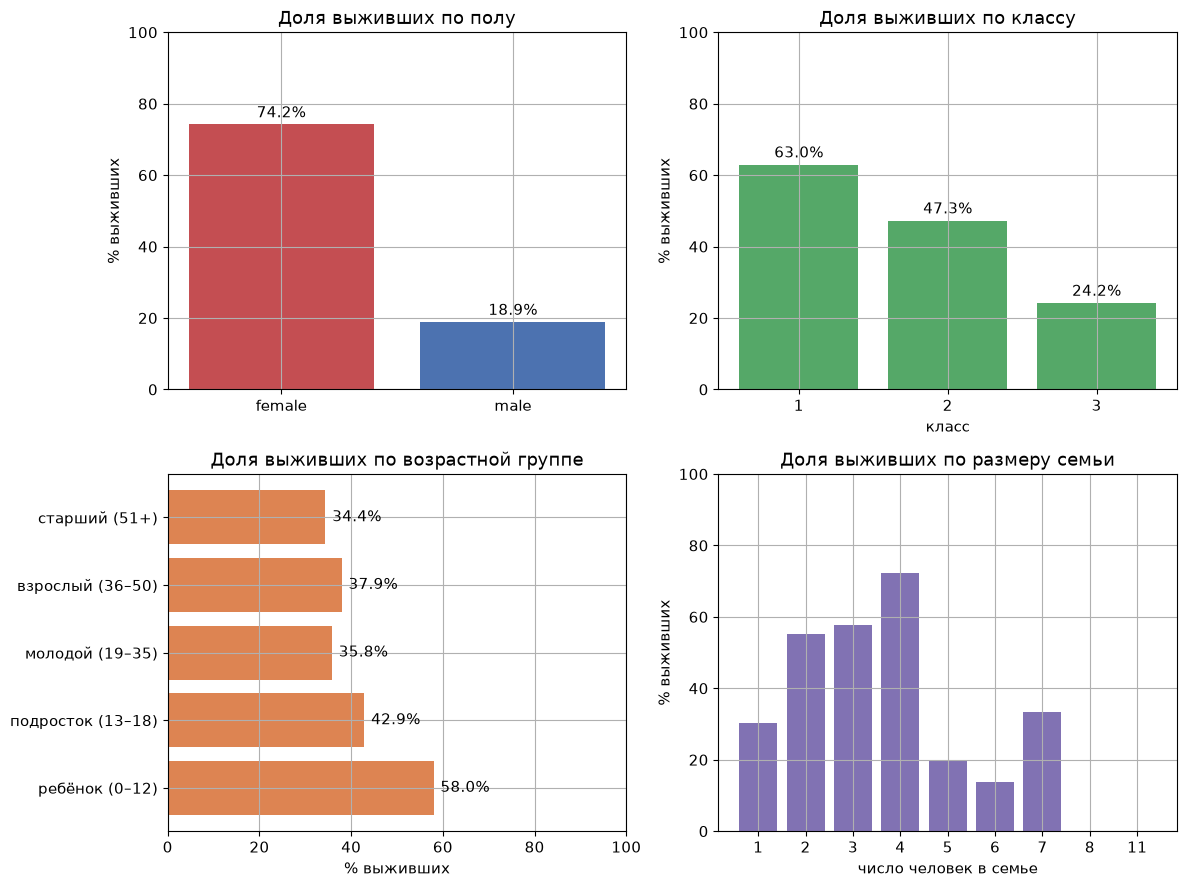

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sex_rate = passengers.groupby("Sex")["Survived"].mean() * 100
axes[0, 0].bar(sex_rate.index, sex_rate.values, color=["#c44e52", "#4c72b0"])
axes[0, 0].set_title("Доля выживших по полу")
axes[0, 0].set_ylabel("% выживших")
axes[0, 0].set_ylim(0, 100)
for tick, value in enumerate(sex_rate.values):
    axes[0, 0].text(tick, value + 2, f"{value:.1f}%", ha="center")

class_rate = passengers.groupby("Pclass")["Survived"].mean() * 100
axes[0, 1].bar(class_rate.index.astype(str), class_rate.values, color="#55a868")
axes[0, 1].set_title("Доля выживших по классу")
axes[0, 1].set_xlabel("класс")
axes[0, 1].set_ylabel("% выживших")
axes[0, 1].set_ylim(0, 100)
for tick, value in enumerate(class_rate.values):
    axes[0, 1].text(tick, value + 2, f"{value:.1f}%", ha="center")

age_rate = passengers.groupby("AgeGroup", observed=True)["Survived"].mean() * 100
axes[1, 0].barh(age_rate.index.astype(str), age_rate.values, color="#dd8452")
axes[1, 0].set_title("Доля выживших по возрастной группе")
axes[1, 0].set_xlabel("% выживших")
axes[1, 0].set_xlim(0, 100)
for tick, value in enumerate(age_rate.values):
    axes[1, 0].text(value + 1.5, tick, f"{value:.1f}%", va="center")

family_rate = passengers.groupby("FamilySize")["Survived"].mean() * 100
axes[1, 1].bar(family_rate.index.astype(str), family_rate.values, color="#8172b3")
axes[1, 1].set_title("Доля выживших по размеру семьи")
axes[1, 1].set_xlabel("число человек в семье")
axes[1, 1].set_ylabel("% выживших")
axes[1, 1].set_ylim(0, 100)

fig.tight_layout()
plt.show()


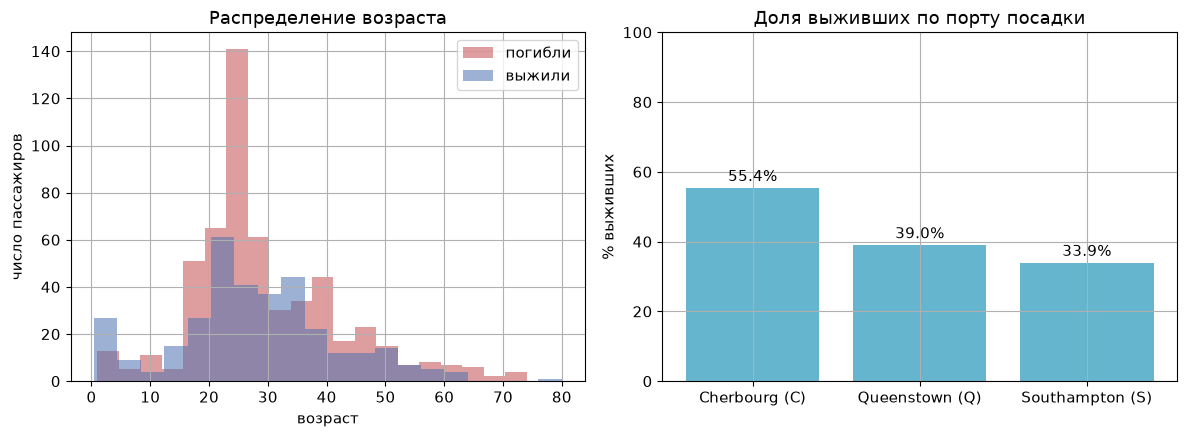

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for survived_flag, label, color in [
    (0, "погибли", "#c44e52"),
    (1, "выжили", "#4c72b0"),
]:
    sample = passengers.loc[passengers["Survived"] == survived_flag, "Age"]
    axes[0].hist(sample, bins=20, alpha=0.55, label=label, color=color)
axes[0].set_title("Распределение возраста")
axes[0].set_xlabel("возраст")
axes[0].set_ylabel("число пассажиров")
axes[0].legend()

port_rate = passengers.groupby("Embarked")["Survived"].mean() * 100
port_labels = {"C": "Cherbourg (C)", "Q": "Queenstown (Q)", "S": "Southampton (S)"}
axes[1].bar([port_labels[p] for p in port_rate.index], port_rate.values, color="#64b5cd")
axes[1].set_title("Доля выживших по порту посадки")
axes[1].set_ylabel("% выживших")
axes[1].set_ylim(0, 100)
for tick, value in enumerate(port_rate.values):
    axes[1].text(tick, value + 2, f"{value:.1f}%", ha="center")

fig.tight_layout()
plt.show()


## 12. Сохранение результатов и проверка

Очищенную таблицу с новыми признаками записываю в `titanic_processed.csv`, а сводку по классу и полу — в `titanic_statistics.csv`. Файлы сохраняются без индекса, в кодировке `utf-8-sig` (её удобно открывать и в Excel). После записи заново читаю обработанный CSV и сверяю его с таблицей в памяти.


In [14]:
# Категории при записи в CSV становятся обычным текстом, поэтому заранее приводим тип
passengers_to_save = passengers.copy()
passengers_to_save["AgeGroup"] = passengers_to_save["AgeGroup"].astype(str)

passengers_to_save.to_csv("titanic_processed.csv", index=False, encoding="utf-8-sig")
by_class_sex.to_csv("titanic_statistics.csv", index=False, encoding="utf-8-sig")

reloaded = pd.read_csv("titanic_processed.csv")
pd.testing.assert_frame_equal(
    passengers_to_save.reset_index(drop=True),
    reloaded,
    check_dtype=False,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12,
)
print("Проверка прошла: titanic_processed.csv совпадает с таблицей в памяти.")
print("Строк и столбцов в сохранённом файле:", reloaded.shape)
display(reloaded.head())
display(pd.read_csv("titanic_statistics.csv"))


Проверка прошла: titanic_processed.csv совпадает с таблицей в памяти.
Строк и столбцов в сохранённом файле: (891, 16)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin,Title,FamilySize,IsAlone,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0,Mr,2,0,молодой (19–35)
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1,Mrs,2,0,взрослый (36–50)
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0,Miss,1,1,молодой (19–35)
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1,Mrs,2,0,молодой (19–35)
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0,Mr,1,1,молодой (19–35)


,Pclass,Sex,PassengerCount,MeanAge,SurvivalPercent,MeanFare
0,1,female,94,34.648936,96.808511,106.125798
1,1,male,122,41.060820,36.885246,67.226127
2,2,female,76,28.703947,92.105263,21.970121
3,2,male,108,30.678981,15.740741,19.741782
4,3,female,144,21.677083,50.000000,16.118810
5,3,male,347,26.099193,13.544669,12.661633


## 13. Выводы

1. Больше всего пропусков было в `Cabin` (77,10%) и в `Age` (19,87%). В `Embarked` не хватало всего двух значений (0,22%).
2. Возраст я заполнил медианой внутри групп «класс + пол», порт посадки — самым частым значением `S`, каюту заменил флагом `HasCabin` и удалил исходный столбец. Все 891 строка сохранились, пропусков не осталось. В итоговой таблице 16 столбцов: исходные поля без `Cabin` и новые признаки `HasCabin`, `Title`, `FamilySize`, `IsAlone`, `AgeGroup`.
3. После заполнения возраста среднее снизилось с 29,70 до 29,11, стандартное отклонение — с 14,53 до 13,30, общая медиана — с 28 до 26 лет, потому что большинство пропусков было в третьем классе. Минимум и максимум не изменились. Полностью исходное распределение не сохраняется: на месте пропусков появляются повторённые групповые медианы.
4. Выживаемость женщин составила 74,20%, мужчин — 18,89%, общая доля выживших — 38,38%. Среди классов обслуживания лучший показатель у первого (62,96%). Дети 0–12 лет спасались чаще взрослых (57,97%). Пассажиры, которые ехали семьёй из 2–4 человек, выживали чаще одиночек (30,35%) и очень больших семей.
5. На практике из pandas особенно пригодились загрузка и сохранение CSV, работа с пропусками, `groupby`/`agg`, фильтрация по нескольким условиям и `transform`. NumPy удобен, когда уже есть массивы и нужно быстро посчитать средние и доли через маски. Графики matplotlib делают те же результаты нагляднее.

Итог: пройден полный цикл базового анализа табличных данных — от первого осмотра и очистки до группировок, графиков, выводов и проверки сохранённых файлов.
